# Physics-Informed Neural Networks used on the reduced 2D Asian Option pricing PDE

- we first reduced the 3D Asian Option pricing PDE by the Večeř dimension reduction

### Imports and setup

In [5]:
%load_ext autoreload
%autoreload 2

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [6]:
# Make sure the /methods folder is included in the path
import sys
from pathlib import Path

sys.path.insert(0, str(Path.cwd().parents[1]))

In [7]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from methods import pinns_applied_on_vecer_reduced_2d_pde as vp
from methods.monte_carlo_control_variate import AsianOptionMC


In [10]:
cfg = vp.Config(
    # training box (z = 1 - K/S0 at inception, so z in [-1, 1] covers S0/K >= 0.5)
    T=1.0, z_min=-1.0, z_max=1.0, r_max=0.1, sigma_max=0.5,
    # network
    width=64, depth=4,
    # optimisation
    epochs=50_000, lr=1e-3, n_pde=2000, n_bc=200, w_pde=1.0,
    # misc
    seed=0, log_every=5000,
)
run_dir = 'runs/w40_e40k_2d'
cfg

Config(T=1.0, z_min=-1.0, z_max=1.0, r_max=0.1, sigma_max=0.5, width=64, depth=4, normalize_inputs=True, epochs=50000, lr=0.001, n_pde=2000, n_bc=200, w_pde=1.0, seed=0, dtype='float32', log_every=5000, device='cpu')

### Training

In [11]:
model = vp.train(cfg, run_dir)

device=cpu  params=12865  epochs=50000
       1  loss=4.617e-01  pde=6.223e-05  data=4.616e-01  lr=1.00e-03  t=0s
    5000  loss=1.456e-05  pde=7.849e-06  data=6.713e-06  lr=9.76e-04  t=221s
   10000  loss=5.031e-06  pde=2.764e-06  data=2.267e-06  lr=9.05e-04  t=439s
   15000  loss=1.686e-06  pde=1.024e-06  data=6.622e-07  lr=7.94e-04  t=653s
   20000  loss=4.951e-06  pde=8.851e-07  data=4.066e-06  lr=6.55e-04  t=868s
   25000  loss=1.146e-06  pde=7.348e-07  data=4.109e-07  lr=5.00e-04  t=1062s
   30000  loss=9.411e-07  pde=4.175e-07  data=5.236e-07  lr=3.45e-04  t=1251s
   35000  loss=5.055e-07  pde=3.125e-07  data=1.931e-07  lr=2.06e-04  t=1442s
   40000  loss=6.031e-07  pde=2.133e-07  data=3.898e-07  lr=9.55e-05  t=1634s
   45000  loss=5.638e-07  pde=1.878e-07  data=3.760e-07  lr=2.45e-05  t=1825s
   50000  loss=3.395e-07  pde=1.934e-07  data=1.461e-07  lr=0.00e+00  t=2017s
saved to runs\w40_e40k_2d/  (training time 2017s)


Reusing an already trained model

In [12]:
# model, cfg = vp.load_model(run_dir)

### Loss history

Text(0, 0.5, 'MSE')

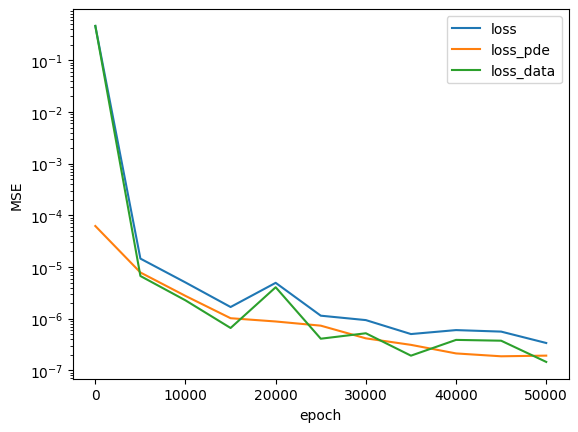

In [14]:
log = pd.read_csv(f"{run_dir}/loss_log.csv")
ax = log.plot(x="epoch", y=["loss", "loss_pde", "loss_data"], logy=True)
ax.set_ylabel("MSE")

### Prices against reference

In [15]:
K, r, T = 100.0, 0.05, 1.0
rows = []
for S in [90.0, 100.0, 110.0]:
    for sigma in [0.1, 0.2, 0.3]:
        mc, mc_lo, mc_hi = AsianOptionMC("call", S, K, T, 100, r, 0.0, sigma, 1_000_000,
                                         average="continuous").value_with_control_variate
        rows.append({
            "S": S, "sigma": sigma,
            "MC": mc, "MC_half_width": (mc_hi - mc_lo) / 2,
            "FD": vp.fd_reference([S], K, T, r, sigma)[0],
            "PINN": vp.price(model, cfg, [S], K, r, sigma)[0],
        })
prices = pd.DataFrame(rows).set_index(["S", "sigma"])
prices["PINN - FD"] = prices["PINN"] - prices["FD"]
print("mean |PINN - FD|:", prices["PINN - FD"].abs().mean(), "  max:", prices["PINN - FD"].abs().max())
prices.style.format("{:.4f}")

mean |PINN - FD|: 0.008090819808605884   max: 0.014212425213783852


### Price curve

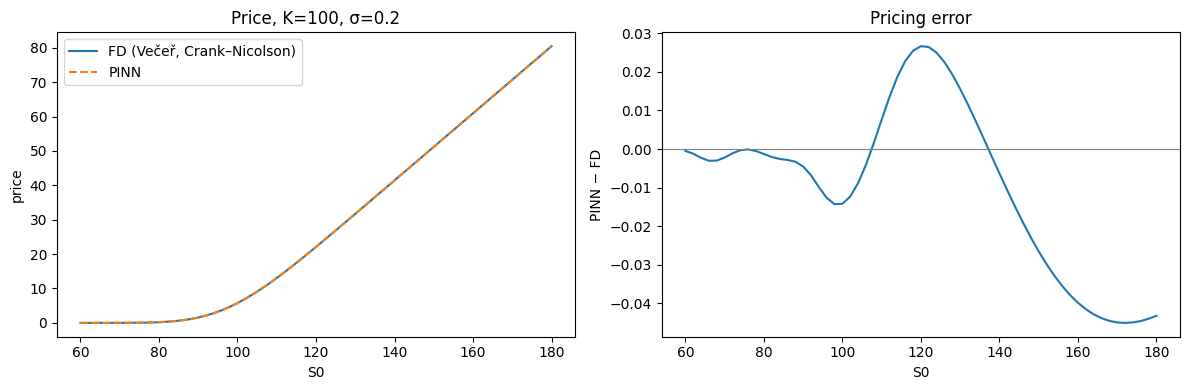

In [16]:
sigma = 0.2
S_grid = np.linspace(60, 180, 61)
V_pinn = vp.price(model, cfg, S_grid, K, r, sigma)
V_fd = vp.fd_reference(S_grid, K, T, r, sigma)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4))
ax1.plot(S_grid, V_fd, label="FD (Večeř, Crank–Nicolson)")
ax1.plot(S_grid, V_pinn, "--", label="PINN")
ax1.set(xlabel="S0", ylabel="price", title=f"Price, K={K:.0f}, σ={sigma}")
ax1.legend()
ax2.plot(S_grid, V_pinn - V_fd)
ax2.axhline(0, color="grey", linewidth=0.8)
ax2.set(xlabel="S0", ylabel="PINN − FD", title="Pricing error")
plt.tight_layout()

### The Greeks

In [17]:
rows = []
for sigma in [0.1, 0.2, 0.3]:
    g = vp.greeks(model, cfg, [90.0, 100.0, 110.0], K, r, sigma)
    for i, S in enumerate([90.0, 100.0, 110.0]):
        rows.append({"S": S, "sigma": sigma, **{k: float(v[i]) for k, v in g.items()}})
greeks_df = pd.DataFrame(rows).set_index(["S", "sigma"]).sort_index()
greeks_df["vega_1%"] = greeks_df["vega"] / 100
greeks_df["rho_1%"] = greeks_df["rho"] / 100
greeks_df["theta_day"] = greeks_df["theta"] / 365
cols = ["price", "delta", "gamma", "vega_1%", "rho_1%", "theta_day", "delta_I", "dual_delta"]
greeks_df[cols].style.format("{:.4f}")

### PINNs Greeks compared to the finite difference greeks

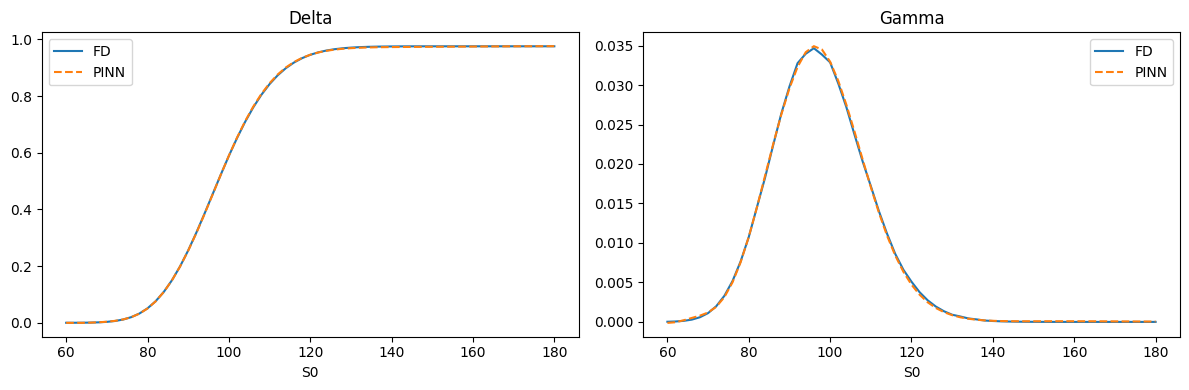

In [18]:
sigma, h = 0.2, 0.5
g = vp.greeks(model, cfg, S_grid, K, r, sigma)
fd_up, fd_mid, fd_dn = (vp.fd_reference(S_grid + d, K, T, r, sigma) for d in (h, 0.0, -h))

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4))
ax1.plot(S_grid, (fd_up - fd_dn) / (2 * h), label="FD")
ax1.plot(S_grid, g["delta"], "--", label="PINN")
ax1.set(xlabel="S0", title="Delta"); ax1.legend()
ax2.plot(S_grid, (fd_up - 2 * fd_mid + fd_dn) / h**2, label="FD")
ax2.plot(S_grid, g["gamma"], "--", label="PINN")
ax2.set(xlabel="S0", title="Gamma"); ax2.legend()
plt.tight_layout()

### Pricing during the averaging period

In [19]:
t, avg_so_far = 0.5, 105.0          # halfway through, average so far 105
vp.price(model, cfg, [95.0, 100.0, 105.0], K, r, 0.2, t=t, I=t * avg_so_far)

array([1.8492057, 3.5020928, 5.591388 ], dtype=float32)